import libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import io
from skimage import color
from skimage import filters
from skimage import img_as_float

plt.rcParams['figure.figsize'] = [15, 5]

Loading image

Image shape: (956, 1300, 3)
Image type: float64
Minimum value: 0.0
Maximum value: 1.0


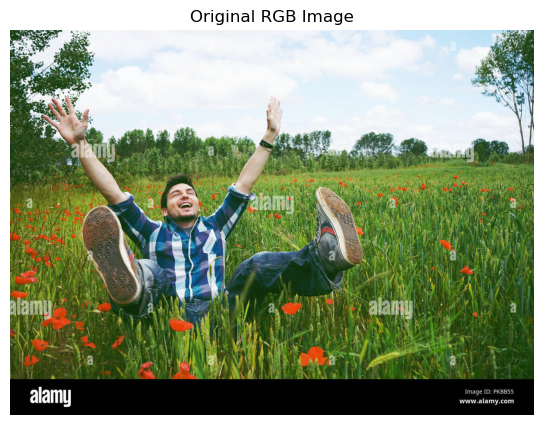

In [4]:
image_path = r"C:\Users\Admin\Downloads\young-man-enjoying-a-spring-day-in-nature-PKBB55.jpg"

im = io.imread(image_path)

# Keep only RGB channels if image has alpha channel
if im.shape[-1] == 4:
    im = im[:, :, :3]

# Convert image to float format between 0 and 1
im = img_as_float(im)

print("Image shape:", im.shape)
print("Image type:", im.dtype)
print("Minimum value:", im.min())
print("Maximum value:", im.max())

plt.imshow(im)
plt.title("Original RGB Image")
plt.axis("off")
plt.show()

Convert RGB image to YCbCr

In [16]:
im_ycbcr = color.rgb2ycbcr(im)

Y = im_ycbcr[:, :, 0]
Cb = im_ycbcr[:, :, 1]
Cr = im_ycbcr[:, :, 2]

print("YCbCr image shape:", im_ycbcr.shape)   


YCbCr image shape: (956, 1300, 3)


Visualize Y, Cb, and Cr channels

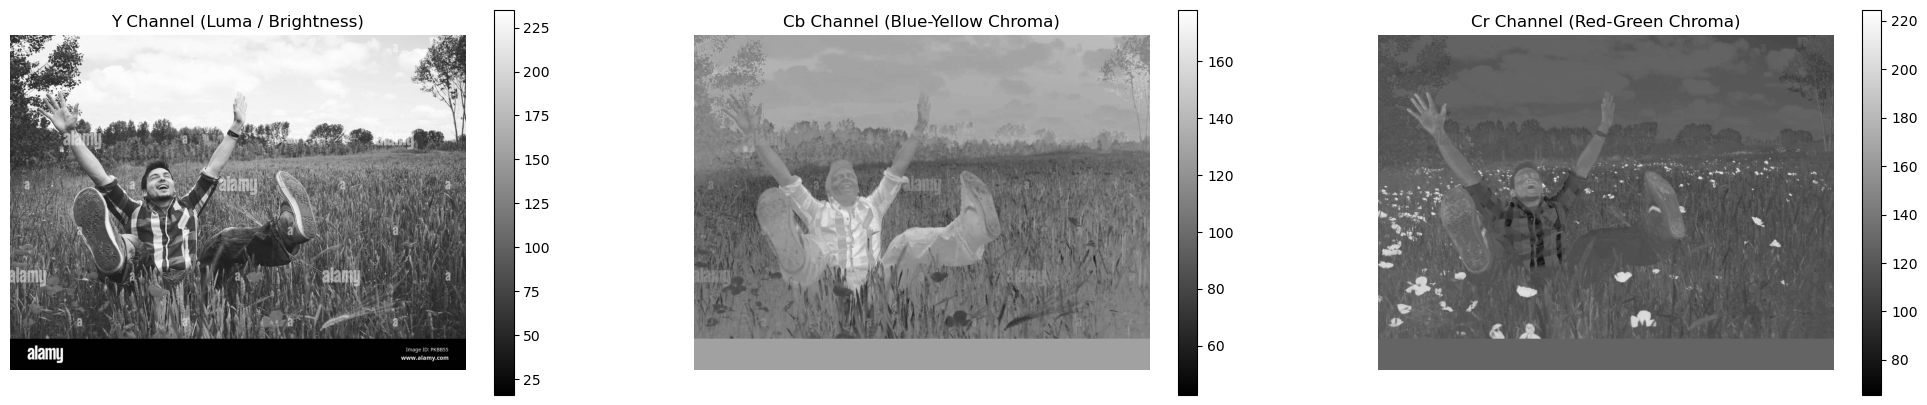

In [17]:
plt.figure(figsize=(25, 5))

plt.subplot(1, 3, 1)
plt.imshow(Y, cmap="gray")
plt.title("Y Channel (Luma / Brightness)")
plt.axis("off")
plt.colorbar()

plt.subplot(1, 3, 2)
plt.imshow(Cb, cmap="gray")
plt.title("Cb Channel (Blue-Yellow Chroma)")
plt.axis("off")
plt.colorbar()

plt.subplot(1, 3, 3)
plt.imshow(Cr, cmap="gray")
plt.title("Cr Channel (Red-Green Chroma)")
plt.axis("off")
plt.colorbar()

plt.show()

Create function to blur only chroma channels

This blurs Cb and Cr only, while keeping Y unchanged.

In [18]:
def compress_CbCr(im, sigma):
    """
    Blur only the chroma channels Cb and Cr.
    The luma channel Y is kept unchanged.
    """

    im_float = img_as_float(im)

    if im_float.shape[-1] == 4:
        im_float = im_float[:, :, :3]

    ycbcr = color.rgb2ycbcr(im_float)

    compressed = ycbcr.copy()

    compressed[:, :, 1] = filters.gaussian(
        ycbcr[:, :, 1],
        sigma=sigma,
        channel_axis=None
    )

    compressed[:, :, 2] = filters.gaussian(
        ycbcr[:, :, 2],
        sigma=sigma,
        channel_axis=None
    )

    rgb_reconstructed = color.ycbcr2rgb(compressed)

    rgb_reconstructed = np.clip(rgb_reconstructed, 0, 1)

    return rgb_reconstructed

Test different blur intensities

In [19]:
sigmas = [1, 3, 7, 15]

Show effect of blurring only chroma channels

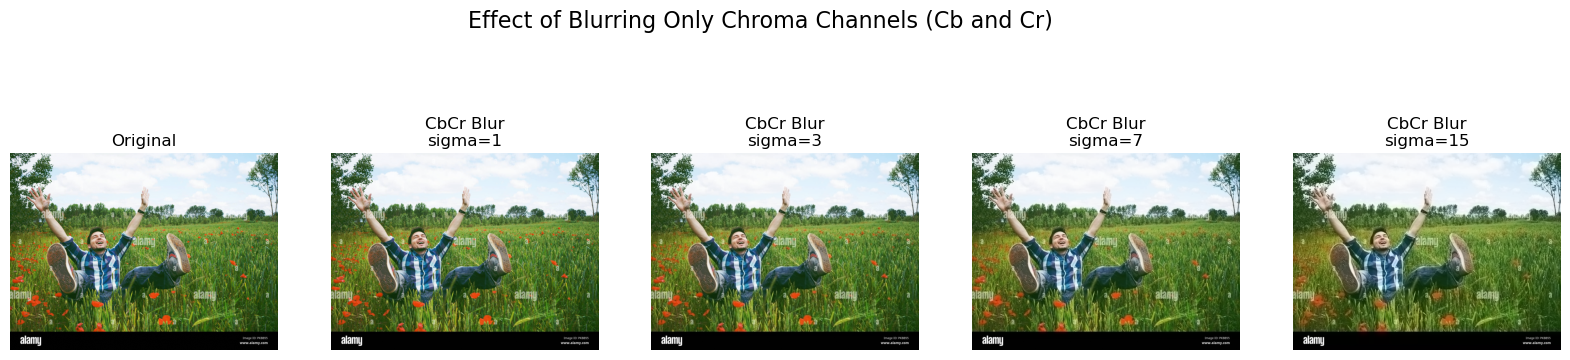

In [25]:
plt.figure(figsize=(20, 5))

plt.subplot(1, len(sigmas) + 1, 1)
plt.imshow(im)
plt.title("Original")
plt.axis("off")

for i, sigma in enumerate(sigmas):

    im_cblur = compress_CbCr(im, sigma)

    plt.subplot(1, len(sigmas) + 1, i + 2)
    plt.imshow(im_cblur)
    plt.title(f"CbCr Blur\nsigma={sigma}")
    plt.axis("off")

plt.suptitle("Effect of Blurring Only Chroma Channels (Cb and Cr)", fontsize=16)
plt.show()

Observation:
Blurring only the chroma channels mainly smooths the color information.
Even with strong blur, the image remains relatively sharp because the luma channel,
which contains most brightness and edge details, is preserved.

Show effect of blurring only luma channel

In [27]:
from skimage import color, filters, img_as_float
import numpy as np

def compress_Y(im, sigma):

    im_float = img_as_float(im)

    # Remove alpha channel if present
    if len(im_float.shape) == 3 and im_float.shape[2] == 4:
        im_float = im_float[:, :, :3]

    ycbcr = color.rgb2ycbcr(im_float)

    compressed = ycbcr.copy()

    # Blur only Y channel
    compressed[:, :, 0] = filters.gaussian(
        ycbcr[:, :, 0],
        sigma=sigma,
        channel_axis=None
    )

    rgb_reconstructed = color.ycbcr2rgb(compressed)

    return np.clip(rgb_reconstructed, 0, 1)

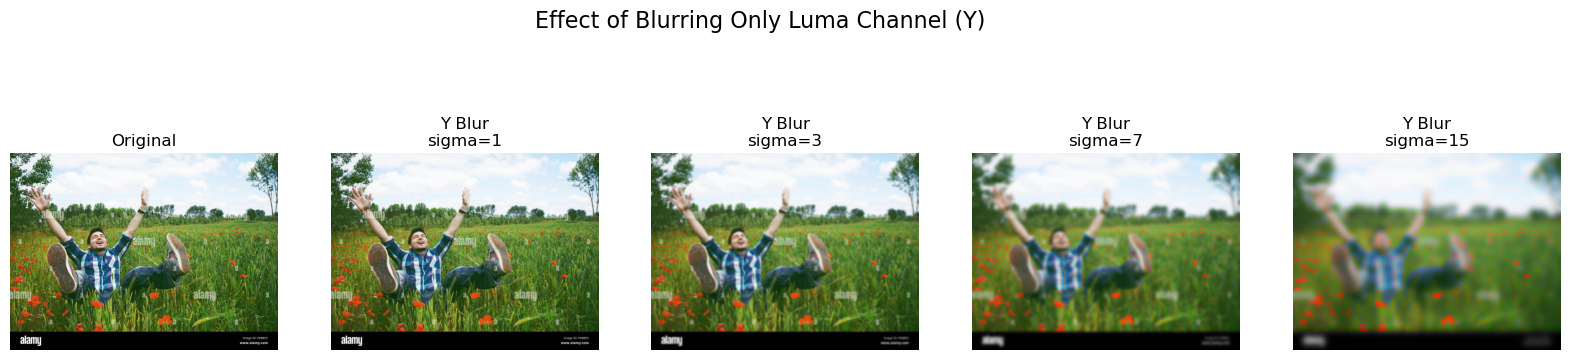

In [28]:
plt.figure(figsize=(20, 5))

plt.subplot(1, len(sigmas) + 1, 1)
plt.imshow(im)
plt.title("Original")
plt.axis("off")

for i, sigma in enumerate(sigmas):

    im_yblur = compress_Y(im, sigma)

    plt.subplot(1, len(sigmas) + 1, i + 2)
    plt.imshow(im_yblur)
    plt.title(f"Y Blur\nsigma={sigma}")
    plt.axis("off")

plt.suptitle("Effect of Blurring Only Luma Channel (Y)", fontsize=16)
plt.show()


Observation:
Blurring only the luma channel causes a strong loss of sharpness and detail.
Edges become unclear and the image looks visibly degraded, even though the color
channels are still preserved.

Direct comparison at same blur intensity

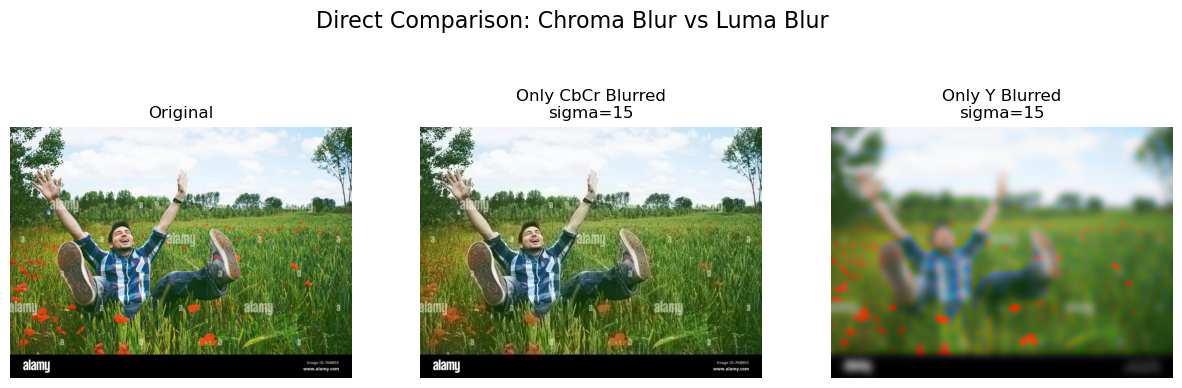

In [29]:
sigma_compare = 15

im_cblur = compress_CbCr(im, sigma_compare)
im_yblur = compress_Y(im, sigma_compare)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(im)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(im_cblur)
plt.title(f"Only CbCr Blurred\nsigma={sigma_compare}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(im_yblur)
plt.title(f"Only Y Blurred\nsigma={sigma_compare}")
plt.axis("off")

plt.suptitle("Direct Comparison: Chroma Blur vs Luma Blur", fontsize=16)
plt.show()

Blurring only the CbCr (chroma) channels has little effect on image quality, while blurring only the Y (luma) channel causes a significant loss of sharpness and detail. This shows that image quality depends more on the luma channel than on the chroma channels.